# Multi-modal MI detection on PTB-XL: end-to-end notebook
Replication attempt of Setu et al. 2025 (ECG signal LSTM + ECG image CNN + attention fusion) on **PTB-XL only**.
Task: MI (any MI code, 5,469) vs. pure Normal (9,069). Split: folds 1-8 train / 9 val / 10 test (patient-wise).
Everything below is executed top to bottom; trained runs are cached in `runs/` so re-execution resumes.
Test fold 10 is scored once per model in section 7, after every choice is frozen on validation.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings('ignore')
os.chdir(os.path.abspath('..')); sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from src import config
from src.labels import build_labels, split_of
from src.train import fit_cached, get_data, predict, _batch
from src.evaluate import *
from src.utils import get_device
%matplotlib inline
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('device', get_device(), '| torch', torch.__version__)

device cuda | torch 2.14.1+cu130


## 1. Data and label rule (frozen in Phase 1)

In [2]:
lab = build_labels(); lab['split'] = lab['fold'].map(split_of)
tab = lab.groupby('split').agg(n=('y','size'), mi=('y','sum'), patients=('patient_id','nunique'))
tab['mi_%'] = (100*tab.mi/tab.n).round(1); display(tab)
print('patient overlap train/val/test:', len(set(lab[lab.split=='train'].patient_id)&set(lab[lab.split!='train'].patient_id)))
age = lab.age.replace(300, 90)
print(lab.assign(age=age).groupby('y').agg(age=('age','mean'), male=('sex', lambda s:(s==1).mean())).round(2))

,n,mi,patients,mi_%
split,,,,
test,1462,550,1297,37.6
train,11622,4379,10396,37.7
val,1454,540,1338,37.1


patient overlap train/val/test: 0
     age  male
y             
0  52.12  0.55
1  66.79  0.38


## 2. Signals and rendered images (Phases 2-3)
Band-pass 0.5-40 Hz, per-lead z-score with train-fold statistics. Images: 12 stacked rows, 224x224, trace bright on dark, fixed ±3 mV per row. `paper` profile = 100 time steps, axis labels, JPEG; `ours` = 1000 steps, no text, lossless.

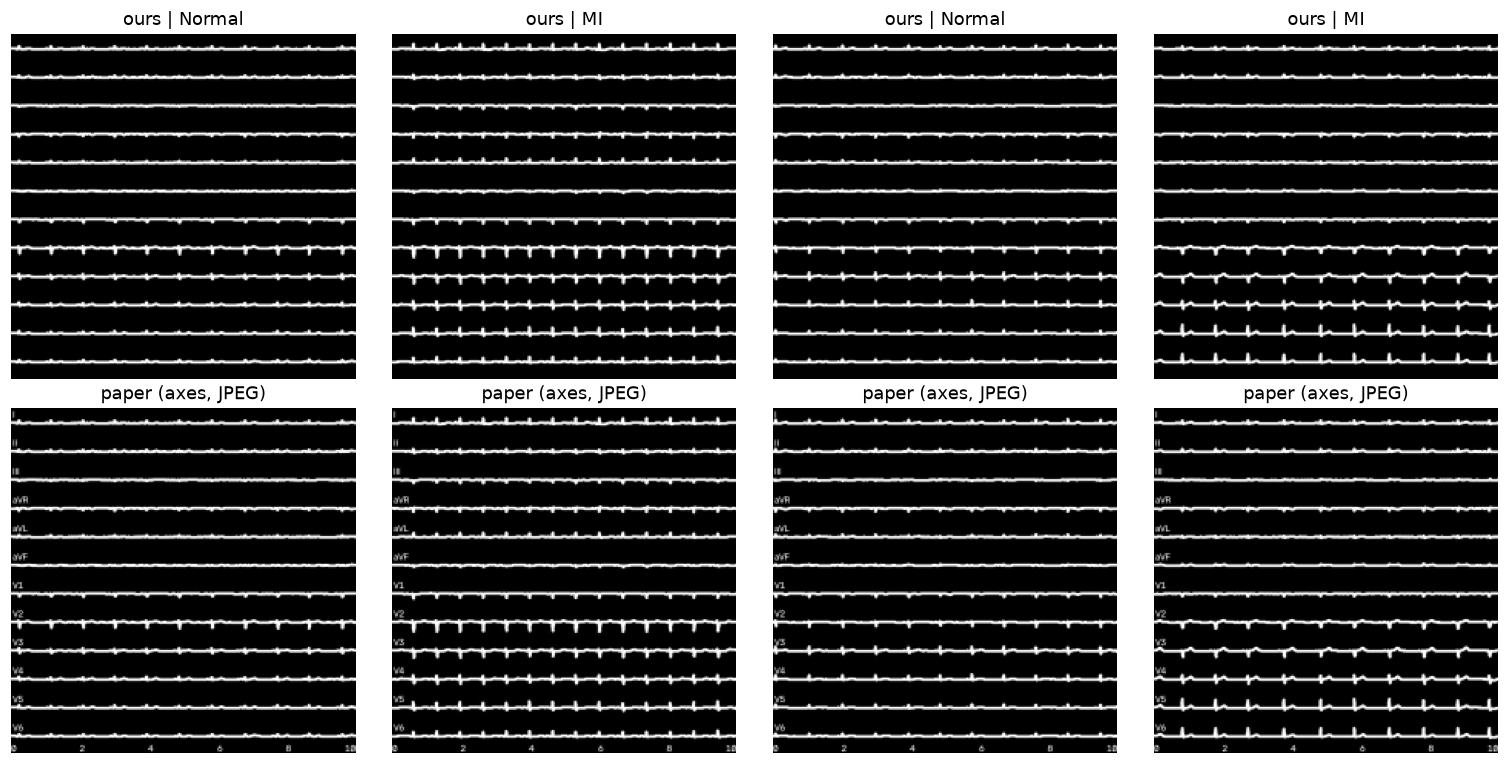

signals (14538, 1000, 12) finite True | train-fold mean/std -0.0 1.016
N images == N signals == N labels: True


In [3]:
from src.images import load_images
from src.signals import load_signals
ims_o, ims_p = load_images('ours'), load_images('paper')
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j, i in enumerate([0, 1, 2, 3]):
    k = np.where(lab.y.values == (j % 2))[0][j]
    ax[0, j].imshow(ims_o[k], cmap='gray'); ax[0, j].set_title(f"ours | {'MI' if lab.y.iloc[k] else 'Normal'}")
    ax[1, j].imshow(ims_p[k], cmap='gray'); ax[1, j].set_title('paper (axes, JPEG)')
    [a.axis('off') for a in ax[:, j]]
plt.tight_layout(); plt.savefig(config.FIGURES_DIR/'render_grid.png'); plt.show()
x = load_signals(1000); print('signals', x.shape, 'finite', np.isfinite(x).all(), '| train-fold mean/std', x[(lab.split=='train').values].mean().round(3), x[(lab.split=='train').values].std().round(3))
# same-ecg_id sanity: image and signal for one record share the index
print('N images == N signals == N labels:', len(ims_o) == len(x) == len(lab))

## 3. Unimodal baselines (validation only, 3 seeds for cheap models)
B1 paper LSTM (100 steps) · B2 ResNet-1D (1000 steps) · B3 paper CNN (image, 224²). Adam, batch 32 (paper), early stopping on val AUROC. Trained on an RTX 3060 (CUDA; bf16 convs in the CNN branch).

In [4]:
yv = get_data('ours')['y'][get_data('ours')['split']=='val']
R = {}
for s in range(config.N_SEEDS):
    R[f'B1_s{s}'] = fit_cached('B1_lstm', f'B1_lstm_s{s}', seed=42+s, profile='paper', max_epochs=30, patience=6)
    R[f'B2_s{s}'] = fit_cached('B2_resnet1d', f'B2_resnet1d_s{s}', seed=42+s, profile='ours', max_epochs=25, patience=5)
R['B3_s0'] = fit_cached('B3_cnn', 'B3_cnn_s0', seed=42, profile='paper', bs=32, max_epochs=30, patience=5)
rows = []
for k, r in R.items():
    lo, hi = bootstrap_ci(yv, r['p_val']); rows.append(dict(run=k, val_auroc=round(r['val_auroc'],4), ci=f'[{lo:.3f}, {hi:.3f}]', epochs=r['epochs']))
base = pd.DataFrame(rows); display(base)
print(base.assign(m=base.run.str.split('_').str[0]).groupby('m').val_auroc.agg(['mean','std']).round(4))

B1_lstm_s0 ep00 loss 0.5148 val_auc 0.8760 (1s)


B1_lstm_s0 ep01 loss 0.4157 val_auc 0.8228 (3s)


B1_lstm_s0 ep02 loss 0.3746 val_auc 0.8646 (4s)


B1_lstm_s0 ep03 loss 0.3629 val_auc 0.9057 (5s)


B1_lstm_s0 ep04 loss 0.3582 val_auc 0.9087 (6s)


B1_lstm_s0 ep05 loss 0.3545 val_auc 0.9115 (7s)


... (121 outputs left out)

B3_cnn_s0 ep28 loss 0.2034 val_auc 0.9665 (248s)


B3_cnn_s0 ep29 loss 0.2003 val_auc 0.9635 (257s)


,run,val_auroc,ci,epochs
0,B1_s0,0.9515,"[0.940, 0.962]",20
1,B2_s0,0.9729,"[0.965, 0.980]",15
2,B1_s1,0.9524,"[0.940, 0.963]",20
3,B2_s1,0.9757,"[0.969, 0.982]",14
4,B1_s2,0.9522,"[0.941, 0.962]",17
5,B2_s2,0.9738,"[0.966, 0.980]",13
6,B3_s0,0.9665,"[0.957, 0.975]",30


      mean     std
m                 
B1  0.9520  0.0005
B2  0.9741  0.0014
B3  0.9665     NaN


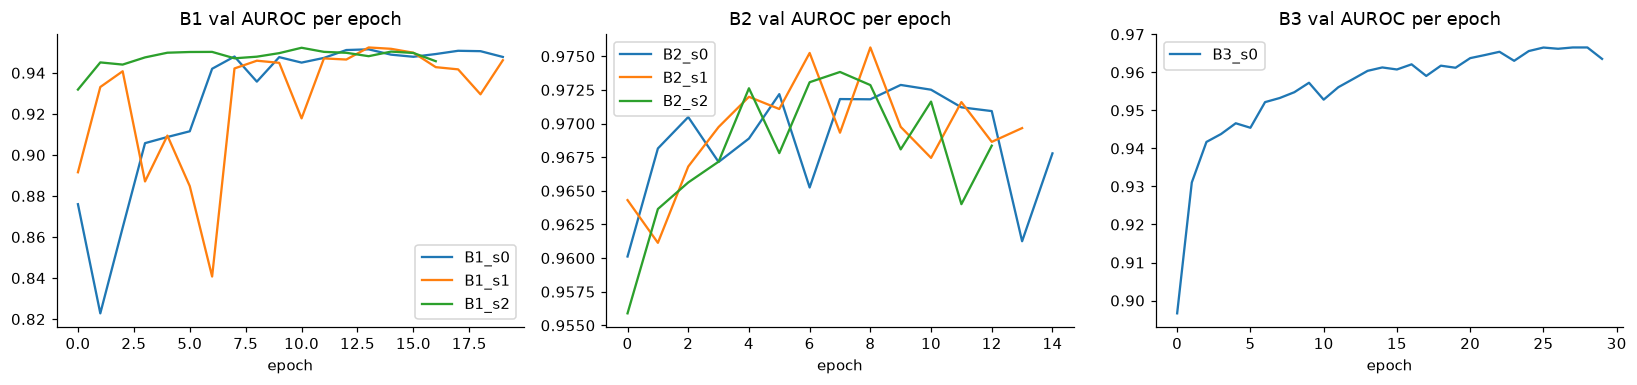

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, pre in zip(ax, ['B1','B2','B3']):
    for k, r in R.items():
        if k.startswith(pre): a.plot([h['val_auroc'] for h in r['history']], label=k); 
    a.set_title(pre+' val AUROC per epoch'); a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.savefig(config.FIGURES_DIR/'baseline_curves.png'); plt.show()

## 4. Multi-modal fusion (paper architecture) and controls
CNN branch (image, 128) + LSTM branch (signal, 100 steps, 128) → attention fusion R1 (our reading) / R2 (Keras reading) / concat control; late fusion = mean of B1 and B3 probabilities. Trained end to end from scratch on the `paper` profile.

F_r1_s0 ep00 loss 0.5907 val_auc 0.7312 (10s)


F_r1_s0 ep01 loss 0.4911 val_auc 0.8961 (20s)


F_r1_s0 ep02 loss 0.3472 val_auc 0.9443 (29s)


F_r1_s0 ep03 loss 0.3239 val_auc 0.9354 (39s)


F_r1_s0 ep04 loss 0.2976 val_auc 0.9453 (49s)


F_r1_s0 ep05 loss 0.2845 val_auc 0.9481 (58s)


... (40 outputs left out)

F_concat_s0 ep12 loss 0.2227 val_auc 0.9632 (123s)


F_concat_s0 ep13 loss 0.2169 val_auc 0.9649 (132s)


F_concat_s0 ep14 loss 0.2152 val_auc 0.9644 (142s)


,model,val_auroc,ci
0,B1 LSTM (s0),0.9515,"[0.940, 0.962]"
1,B2 ResNet1D (s0),0.9729,"[0.965, 0.980]"
2,B3 CNN,0.9665,"[0.957, 0.975]"
3,Late fusion B1+B3,0.9644,"[0.955, 0.973]"
4,Concat fusion,0.9650,"[0.956, 0.974]"
5,Attention R1,0.9509,"[0.938, 0.961]"
6,Attention R2,0.9496,"[0.938, 0.961]"


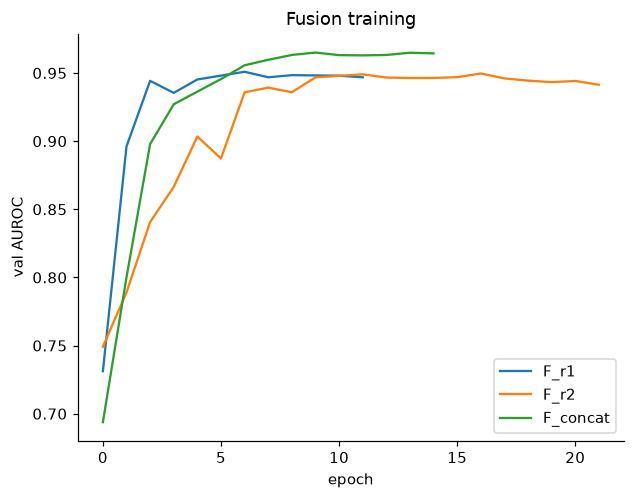

In [6]:
for n in ['F_r1','F_r2','F_concat']:
    R[n] = fit_cached(n, n+'_s0', seed=42, profile='paper', bs=32, max_epochs=30, patience=5)
pl = (R['B1_s0']['p_val'] + R['B3_s0']['p_val'])/2
rows = []
for k, p in [('B1 LSTM (s0)',R['B1_s0']['p_val']),('B2 ResNet1D (s0)',R['B2_s0']['p_val']),('B3 CNN',R['B3_s0']['p_val']),
             ('Late fusion B1+B3',pl),('Concat fusion',R['F_concat']['p_val']),('Attention R1',R['F_r1']['p_val']),('Attention R2',R['F_r2']['p_val'])]:
    lo, hi = bootstrap_ci(yv, p); rows.append(dict(model=k, val_auroc=round(roc_auc_score(yv,p),4), ci=f'[{lo:.3f}, {hi:.3f}]'))
fus = pd.DataFrame(rows); display(fus)
for n in ['F_r1','F_r2','F_concat']:
    h = pd.DataFrame(R[n]['history']); plt.plot(h.val_auroc, label=n)
plt.legend(); plt.xlabel('epoch'); plt.ylabel('val AUROC'); plt.title('Fusion training'); plt.savefig(config.FIGURES_DIR/'fusion_curves.png'); plt.show()

## 5. Tuning (validation only, equal small budget for the two cheap signal models)
Learning rate {3e-4, 1e-3, 3e-3} for B1 and B2 (3 trials each, seed 42). The image and fusion models keep the paper's lr 1e-3 (not tuned); this is stated as a limitation, and it favours the signal baselines.

In [7]:
T = []
for name, prof, ep in [('B1_lstm','paper',30), ('B2_resnet1d','ours',25)]:
    for lr in (3e-4, 1e-3, 3e-3):
        r = fit_cached(name, f'tune_{name}_lr{lr}', seed=42, lr=lr, profile=prof, max_epochs=ep, patience=5)
        T.append(dict(model=name, lr=lr, val_auroc=round(r['val_auroc'],4)))
tune = pd.DataFrame(T); display(tune.pivot(index='lr', columns='model', values='val_auroc'))
best_lr = tune.loc[tune.groupby('model').val_auroc.idxmax()].set_index('model').lr.to_dict(); print('frozen lr:', best_lr)

tune_B1_lstm_lr0.0003 ep00 loss 0.5311 val_auc 0.8906 (1s)


tune_B1_lstm_lr0.0003 ep01 loss 0.3745 val_auc 0.9187 (3s)


tune_B1_lstm_lr0.0003 ep02 loss 0.3387 val_auc 0.9313 (4s)


tune_B1_lstm_lr0.0003 ep03 loss 0.3161 val_auc 0.9105 (5s)


tune_B1_lstm_lr0.0003 ep04 loss 0.3214 val_auc 0.9345 (6s)


tune_B1_lstm_lr0.0003 ep05 loss 0.3034 val_auc 0.9243 (7s)


... (99 outputs left out)

tune_B2_resnet1d_lr0.003 ep20 loss 0.0770 val_auc 0.9697 (50s)


tune_B2_resnet1d_lr0.003 ep21 loss 0.0683 val_auc 0.9661 (53s)


model,B1_lstm,B2_resnet1d
lr,,
0.0003,0.9532,0.9716
0.0010,0.9515,0.9729
0.0030,0.9558,0.9736


frozen lr: {'B1_lstm': 0.003, 'B2_resnet1d': 0.003}


In [8]:
# Frozen final runs: 3 seeds at the tuned lr for B1/B2
FIN = {}
for name, prof, ep, tag in [('B1_lstm','paper',30,'B1'), ('B2_resnet1d','ours',25,'B2')]:
    for s in range(config.N_SEEDS):
        FIN[f'{tag}_s{s}'] = fit_cached(name, f'final_{name}_s{s}', seed=42+s, lr=best_lr[name], profile=prof, max_epochs=ep, patience=5)
for tag in ('B1','B2'):
    a = [FIN[f'{tag}_s{s}']['val_auroc'] for s in range(config.N_SEEDS)]; print(tag, 'val AUROC mean±sd', np.mean(a).round(4), np.std(a).round(4))
FIN['B3'], FIN['F_r1'], FIN['F_r2'], FIN['F_concat'] = R['B3_s0'], R['F_r1'], R['F_r2'], R['F_concat']
# seed-ensemble probabilities for the signal models, single run for the image/fusion models
P_val = {'B1 LSTM': np.mean([FIN[f'B1_s{s}']['p_val'] for s in range(3)],0), 'B2 ResNet1D': np.mean([FIN[f'B2_s{s}']['p_val'] for s in range(3)],0),
         'B3 CNN': R['B3_s0']['p_val'], 'Concat': R['F_concat']['p_val'], 'Attn R1': R['F_r1']['p_val'], 'Attn R2': R['F_r2']['p_val']}
P_test = {'B1 LSTM': np.mean([FIN[f'B1_s{s}']['p_test'] for s in range(3)],0), 'B2 ResNet1D': np.mean([FIN[f'B2_s{s}']['p_test'] for s in range(3)],0),
          'B3 CNN': R['B3_s0']['p_test'], 'Concat': R['F_concat']['p_test'], 'Attn R1': R['F_r1']['p_test'], 'Attn R2': R['F_r2']['p_test']}
P_val['Late B1+B3'] = (P_val['B1 LSTM']+P_val['B3 CNN'])/2; P_test['Late B1+B3'] = (P_test['B1 LSTM']+P_test['B3 CNN'])/2
print(pd.Series({k: round(roc_auc_score(yv,v),4) for k,v in P_val.items()}, name='val AUROC (frozen)'))

final_B1_lstm_s0 ep00 loss 0.4733 val_auc 0.8955 (1s)


final_B1_lstm_s0 ep01 loss 0.3390 val_auc 0.9431 (2s)


final_B1_lstm_s0 ep02 loss 0.3778 val_auc 0.9425 (4s)


final_B1_lstm_s0 ep03 loss 0.2891 val_auc 0.9498 (5s)


final_B1_lstm_s0 ep04 loss 0.2794 val_auc 0.9495 (6s)


final_B1_lstm_s0 ep05 loss 0.2594 val_auc 0.9515 (7s)


... (93 outputs left out)

final_B2_resnet1d_s2 ep10 loss 0.1578 val_auc 0.9695 (26s)


final_B2_resnet1d_s2 ep11 loss 0.1522 val_auc 0.9674 (28s)


final_B2_resnet1d_s2 ep12 loss 0.1395 val_auc 0.9708 (31s)


B1 val AUROC mean±sd 0.954 0.0013
B2 val AUROC mean±sd 0.9731 0.0016
B1 LSTM        0.9579
B2 ResNet1D    0.9762
B3 CNN         0.9665
Concat         0.9650
Attn R1        0.9509
Attn R2        0.9496
Late B1+B3     0.9670
Name: val AUROC (frozen), dtype: float64


## 6. Ablations (validation, paired bootstrap ΔAUROC)
A1/A2 from the frozen models; A3 sequence length for the LSTM; A7 noisy records; A9 augmentation for the CNN is skipped (cost), see report.

In [9]:
rows = []
for a, b in [('Attn R1','B1 LSTM'),('Attn R1','B2 ResNet1D'),('Attn R1','Concat'),('Attn R1','Late B1+B3'),('Attn R1','Attn R2'),('B2 ResNet1D','B1 LSTM'),('B1 LSTM','B3 CNN')]:
    d, lo, hi = paired_delta_auc(yv, P_val[a], P_val[b]); rows.append(dict(A=a, B=b, dAUROC=round(d,4), ci=f'[{lo:.3f}, {hi:.3f}]', sig=('yes' if lo>0 or hi<0 else 'no')))
display(pd.DataFrame(rows))

,A,B,dAUROC,ci,sig
0,Attn R1,B1 LSTM,-0.0069,"[-0.012, -0.002]",yes
1,Attn R1,B2 ResNet1D,-0.0252,"[-0.034, -0.018]",yes
2,Attn R1,Concat,-0.0141,"[-0.022, -0.006]",yes
3,Attn R1,Late B1+B3,-0.0161,"[-0.022, -0.011]",yes
4,Attn R1,Attn R2,0.0013,"[-0.003, 0.005]",no
5,B2 ResNet1D,B1 LSTM,0.0183,"[0.012, 0.026]",yes
6,B1 LSTM,B3 CNN,-0.0087,"[-0.017, -0.001]",yes


In [10]:
# A3: LSTM input length (seed 42, tuned lr). 100 steps = paper profile
A3 = []
for L in (100, 250, 500, 1000):
    r = fit_cached('B1_lstm', f'abl_A3_L{L}', seed=42, lr=best_lr['B1_lstm'], profile='ours', seq_len=L, max_epochs=20 if L<=250 else 12, patience=4)
    A3.append(dict(seq_len=L, val_auroc=round(r['val_auroc'],4)))
display(pd.DataFrame(A3))

abl_A3_L100 ep00 loss 0.4733 val_auc 0.8955 (2s)


abl_A3_L100 ep01 loss 0.3390 val_auc 0.9431 (3s)


abl_A3_L100 ep02 loss 0.3778 val_auc 0.9425 (4s)


abl_A3_L100 ep03 loss 0.2891 val_auc 0.9498 (5s)


abl_A3_L100 ep04 loss 0.2794 val_auc 0.9495 (6s)


abl_A3_L100 ep05 loss 0.2594 val_auc 0.9515 (8s)


... (49 outputs left out)

abl_A3_L1000 ep09 loss 0.1772 val_auc 0.9696 (72s)


abl_A3_L1000 ep10 loss 0.1726 val_auc 0.9712 (79s)


abl_A3_L1000 ep11 loss 0.4417 val_auc 0.6459 (86s)


,seq_len,val_auroc
0,100,0.9558
1,250,0.9696
2,500,0.9731
3,1000,0.9712


In [11]:
# A7: noisy vs clean validation records (baseline drift / static / burst noise flagged)
noisy = lab[['baseline_drift','static_noise','burst_noise','electrodes_problems']].notna().any(axis=1).values
vm = (lab.split=='val').values; nv = noisy[vm]
for k in ['B1 LSTM','B2 ResNet1D','B3 CNN','Attn R1']:
    print(f'{k:12s} clean AUROC {roc_auc_score(yv[~nv],P_val[k][~nv]):.4f} (n={int((~nv).sum())}) | noisy {roc_auc_score(yv[nv],P_val[k][nv]):.4f} (n={int(nv.sum())})')

B1 LSTM      clean AUROC 0.9601 (n=1099) | noisy 0.9543 (n=355)
B2 ResNet1D  clean AUROC 0.9760 (n=1099) | noisy 0.9767 (n=355)
B3 CNN       clean AUROC 0.9678 (n=1099) | noisy 0.9633 (n=355)
Attn R1      clean AUROC 0.9551 (n=1099) | noisy 0.9422 (n=355)
